In [15]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Retrieving customer data with Requests

In [16]:
url = "https://jsonplaceholder.typicode.com/users"

response = requests.get(url, timeout = 12)

print(response.status_code)

200


In [18]:
customers = response.json()

print(type(customers))
print(len(customers))

<class 'list'>
10


In [19]:
customers[0]

{'id': 1,
 'name': 'Leanne Graham',
 'username': 'Bret',
 'email': 'Sincere@april.biz',
 'address': {'street': 'Kulas Light',
  'suite': 'Apt. 556',
  'city': 'Gwenborough',
  'zipcode': '92998-3874',
  'geo': {'lat': '-37.3159', 'lng': '81.1496'}},
 'phone': '1-770-736-8031 x56442',
 'website': 'hildegard.org',
 'company': {'name': 'Romaguera-Crona',
  'catchPhrase': 'Multi-layered client-server neural-net',
  'bs': 'harness real-time e-markets'}}

In [20]:
type(customers[0])

dict

Creating explore(record, indent)

In [21]:
def explore(record, indent=0):
    for key, value in record.items():
        print(" " * indent + f"{key}: {type(value).__name__}")

        if isinstance(value, dict):
            explore(value, indent +2)

        elif isinstance(value, list):
            for item in value:
                if isinstance(item,(dict, list)):
                    explore (item, indent +2)

In [22]:
explore(customers[0])

id: int
name: str
username: str
email: str
address: dict
  street: str
  suite: str
  city: str
  zipcode: str
  geo: dict
    lat: str
    lng: str
phone: str
website: str
company: dict
  name: str
  catchPhrase: str
  bs: str


Converting nested cutomer data to flat customer data

In [24]:
def extract_attributes(customers):
    rows = []

    for customer in customers:
        row = {
            "id": customer["id"],
            "name": customer["name"],
            "username": customer["username"],
            "email": customer["email"],
            "email_domain": customer["email"].split("@")[-1],
            "phone": customer["phone"],
            "city": customer["address"]["city"],
            "zipcode": customer["address"]["zipcode"],
            "latitude": float(customer["address"]["geo"]["lat"]),
            "longitude": float(customer["address"]["geo"]["lng"]),
            "company": customer["company"]["name"],
            "website": customer["website"]
        }

        rows.append(row)

    return rows

In [25]:
customer_rows = extract_attributes(customers)

print(len(customer_rows))
print(customer_rows[0])

10
{'id': 1, 'name': 'Leanne Graham', 'username': 'Bret', 'email': 'Sincere@april.biz', 'email_domain': 'april.biz', 'phone': '1-770-736-8031 x56442', 'city': 'Gwenborough', 'zipcode': '92998-3874', 'latitude': -37.3159, 'longitude': 81.1496, 'company': 'Romaguera-Crona', 'website': 'hildegard.org'}


Finding unique cities using sets

In [26]:
def unique_cities(customers):
    cities = {
        customer["address"]["city"]
        for customer in customers
    }

    return cities

In [27]:
cities = unique_cities(customers)

print("Total customers:", len(customers))
print("unique cities:", len(cities))
print("Cities:", sorted(cities))

Total customers: 10
unique cities: 10
Cities: ['Aliyaview', 'Bartholomebury', 'Gwenborough', 'Howemouth', 'Lebsackbury', 'McKenziehaven', 'Roscoeview', 'South Christy', 'South Elvis', 'Wisokyburgh']


this means each customer in this sample lives in a different city, so no city appears more than once

Count customers by city

In [29]:
def city_counts(customers):
    counts= {}

    for customer in customers:
        city = customer["address"]["city"]

        if city in counts:
            counts[city] += 1
        else:
            counts[city] = 1

    return counts

In [30]:
cities_count = city_counts(customers)

sorted_cities = sorted(
    cities_count.items(),
    key=lambda item: item[1],
    reverse= True
)
print(sorted_cities)

[('Gwenborough', 1), ('Wisokyburgh', 1), ('McKenziehaven', 1), ('South Elvis', 1), ('Roscoeview', 1), ('South Christy', 1), ('Howemouth', 1), ('Aliyaview', 1), ('Bartholomebury', 1), ('Lebsackbury', 1)]


Count customers by email domain

In [31]:
def email_domain_counts(customers):
    domains = {
        customer["email"].split("@")[-1]
        for customer in customers
    }

    counts = {
        domain: sum(
            1 for customer in customers
            if customer["email"].split("@")[-1] == domain
        )
        for domain in domains
    }
    return counts

In [32]:
domains_count = email_domain_counts(customers)

sorted_domains = sorted(
    domains_count.items(),
    key=lambda item: item[1],
    reverse = True
)
print(sorted_domains)


[('melissa.tv', 1), ('annie.ca', 1), ('dana.io', 1), ('billy.biz', 1), ('yesenia.net', 1), ('jasper.info', 1), ('rosamond.me', 1), ('karina.biz', 1), ('april.biz', 1), ('kory.org', 1)]


Converting customer records into a pandas dataframe

In [33]:
def to_dataframe(rows):
    # Converting the list of customer dict into a table
    df= pd.DataFrame(rows)
    return df

In [34]:
#Creating the dataframe
df= to_dataframe(customer_rows)
display(df.head())

,id,name,username,email,email_domain,phone,city,zipcode,latitude,longitude,company,website
0,1,Leanne Graham,Bret,Sincere@april.biz,april.biz,1-770-736-8031 x56442,Gwenborough,92998-3874,-37.3159,81.1496,Romaguera-Crona,hildegard.org
1,2,Ervin Howell,Antonette,Shanna@melissa.tv,melissa.tv,010-692-6593 x09125,Wisokyburgh,90566-7771,-43.9509,-34.4618,Deckow-Crist,anastasia.net
2,3,Clementine Bauch,Samantha,Nathan@yesenia.net,yesenia.net,1-463-123-4447,McKenziehaven,59590-4157,-68.6102,-47.0653,Romaguera-Jacobson,ramiro.info
3,4,Patricia Lebsack,Karianne,Julianne.OConner@kory.org,kory.org,493-170-9623 x156,South Elvis,53919-4257,29.4572,-164.2990,Robel-Corkery,kale.biz
4,5,Chelsey Dietrich,Kamren,Lucio_Hettinger@annie.ca,annie.ca,(254)954-1289,Roscoeview,33263,-31.8129,62.5342,Keebler LLC,demarco.info


In [35]:
print("DataFrames shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes)

DataFrames shape: (10, 12)

Column data types:
id                int64
name                str
username            str
email               str
email_domain        str
phone               str
city                str
zipcode             str
latitude        float64
longitude       float64
company             str
website             str
dtype: object


In [36]:
print("Plain Python city counts:")
print(city_counts(customers))

print("\nPandas city counts:")
print(df["city"].value_counts())



Plain Python city counts:
{'Gwenborough': 1, 'Wisokyburgh': 1, 'McKenziehaven': 1, 'South Elvis': 1, 'Roscoeview': 1, 'South Christy': 1, 'Howemouth': 1, 'Aliyaview': 1, 'Bartholomebury': 1, 'Lebsackbury': 1}

Pandas city counts:
city
Gwenborough       1
Wisokyburgh       1
McKenziehaven     1
South Elvis       1
Roscoeview        1
South Christy     1
Howemouth         1
Aliyaview         1
Bartholomebury    1
Lebsackbury       1
Name: count, dtype: int64


Exporting data to csv

In [37]:
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(parents= True, exist_ok = True)

In [38]:
customers_path = output_dir / "customers.csv"

df.to_csv(customers_path, index=False)

print("Customer data saved to:", customers_path)


Customer data saved to: output\customers.csv


Exporting the city counts

In [39]:
city_counts_df = pd.DataFrame(
    list(cities_count.items()),
    columns= ["city", "customer_count"]
)

city_counts_df = city_counts_df.sort_values(
    by= "customer_count",
    ascending= False
)

city_counts_path = output_dir / "city_counts.csv"
city_counts_df.to_csv(city_counts_path, index = False)


display(city_counts_df)
print("City counts saved to:", city_counts_path)

,city,customer_count
0,Gwenborough,1
1,Wisokyburgh,1
2,McKenziehaven,1
3,South Elvis,1
4,Roscoeview,1
5,South Christy,1
6,Howemouth,1
7,Aliyaview,1
8,Bartholomebury,1
9,Lebsackbury,1


City counts saved to: output\city_counts.csv


In [40]:
# Confirming the files exist
print("Customers file exists:", customers_path.exists())
print("City counts file exists:", city_counts_path.exists())


Customers file exists: True
City counts file exists: True


Creating and saving the customer distribution chart using matplotlib

In [46]:
def plot_distribution(counts, path):
    # Convert the counts dictionary into a DataFrame
    plot_df = pd.DataFrame(
        list(counts.items()),
        columns=["email_domain", "customer_count"]
    )

    plot_df = plot_df.sort_values(
        by=["customer_count", "email_domain"],
        ascending= [False, True]
    )

    plt.figure(figsize=(10, 6))
    plt.bar(plot_df["email_domain"], plot_df["customer_count"])

    plt.title("Customer Distribution by Email Domain")
    plt.xlabel("Email Domain")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(range(0, max(plot_df["customer_count"]) +2))
    plt.tight_layout()

    # Save and display the chart
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

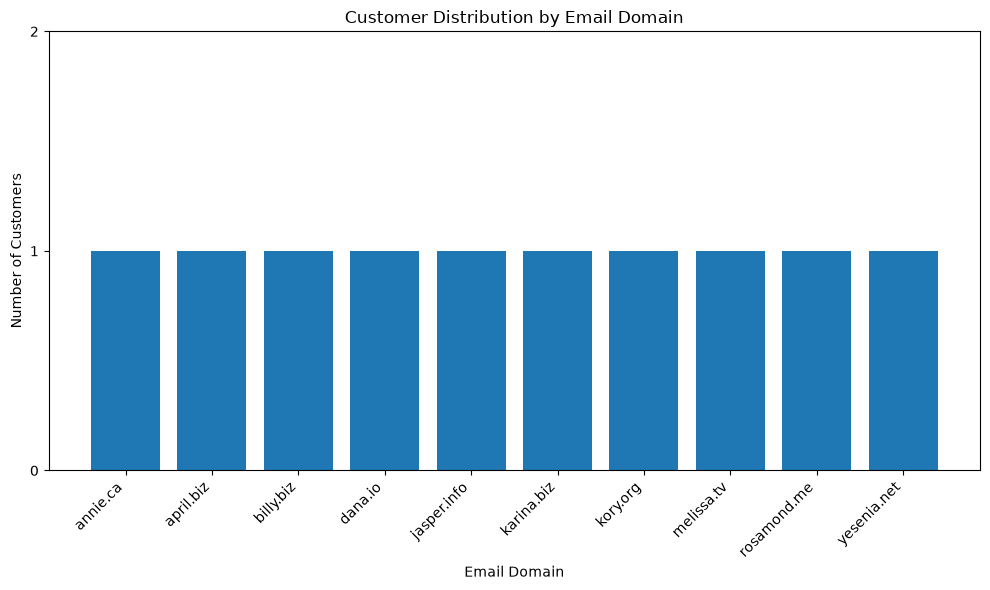

Chart saved: True
Chart location: output\customer_distribution.png


In [47]:
chart_path = output_dir / "customer_distribution.png"

plot_distribution(domains_count, chart_path)

print("Chart saved:", chart_path.exists())
print("Chart location:", chart_path)